# 04 — ARIMA Sales Forecasting on Omnichannel Data

Expanding the comparison to 4 models now: ARIMA joins Prophet and TimesFM as the classical statistical baseline, with LightGBM coming next. Using Auto-ARIMA (`pmdarima`) to fit per-country models without external regressors — a deliberately "pure time-series" baseline that puts the others' use of domain knowledge into perspective.

Runs fine on CPU.

**Walkthrough:**
1. Environment setup
2. Data loading & exploration
3. Preprocessing & train/test split
4. ARIMA model configuration
5. Training (per-country models)
6. Forecasting & evaluation
7. Visualization
8. Exporting results


## Environment setup

Auto-ARIMA from `pmdarima` automates (p,d,q) selection via AIC minimization — runs entirely on CPU.


In [1]:
# Cell 1: Install dependencies
!pip install -q pmdarima pandas numpy scikit-learn matplotlib seaborn

import os
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# ARIMA
import pmdarima as pm
from pmdarima import auto_arima

# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

# Reproducibility
SEED = 42
np.random.seed(SEED)

print(f'pmdarima version: {pm.__version__}')
print('Setup complete.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 11.2 MB/s eta 0:00:00
pmdarima version: 2.1.1
Setup complete.


### Connecting to Google Drive


In [ ]:
# Cell 1b: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/ML_Prediction_Analysis'
DATA_DIR = f'{DRIVE_BASE}/Sample_Data'
RESULTS_DIR = f'{DRIVE_BASE}/ARIMA_Results'

os.makedirs(RESULTS_DIR, exist_ok=True)

SALES_PATH = f'{DATA_DIR}/company_weekly_sales.csv'
FORECAST_HORIZON = 12

print(f'Data dir:     {DATA_DIR}')
print(f'Results dir:  {RESULTS_DIR}')
print(f'Forecast horizon: {FORECAST_HORIZON} weeks')
print('Drive mounted successfully.')

Mounted at /content/drive
Data dir:     /content/drive/MyDrive/ML_Prediction_Analysis/Sample_Data
Results dir:  /content/drive/MyDrive/ML_Prediction_Analysis/ARIMA_Results
Forecast horizon: 12 weeks
Drive mounted successfully.


## Loading and exploring the data


In [3]:
# Cell 2: Load data
sales_df = pd.read_csv(SALES_PATH)
sales_df['week_start_date'] = pd.to_datetime(sales_df['week_start_date'])

print(f'Sales dataset shape: {sales_df.shape}')
print(f'Date range: {sales_df.week_start_date.min()} to '
      f'{sales_df.week_start_date.max()}')
print(f'Countries: {sorted(sales_df.country.unique())}')
sales_df.head()

Sales dataset shape: (3067, 12)
Date range: 2016-03-07 00:00:00 to 2025-12-22 00:00:00
Countries: ['BE', 'DE', 'ES', 'FR', 'IT', 'NL', 'PT', 'UK']


,week_start_date,country,total_revenue_eur,order_count,total_quantity,avg_order_value_eur,discount_amount_eur,top_product_category,channel,promotion_flag,holiday_event,covid_period_flag
0,2016-03-07,IT,0.00,1,1,0.00,0.00,Compléments alimentaires,web,1,epifania,0
1,2016-03-14,IT,834.38,32,75,26.07,68.87,Antiparasitaire,mobile,1,NaN,0
2,2016-03-21,IT,1257.89,29,58,43.38,33.23,Compléments alimentaires,web,0,NaN,0
3,2016-03-28,IT,2190.96,62,120,35.34,103.39,Compléments alimentaires,web,0,NaN,0
4,2016-04-04,IT,2639.80,67,142,39.40,111.66,Ophtalmologie,web,0,NaN,0


## Preprocessing & train/test split

ARIMA works on a single univariate series, so I split per country and hold out the last 12 weeks — same convention as Prophet and TimesFM.

**Note:** I'm deliberately not giving ARIMA any external regressors here. Keeping it a pure time-series baseline makes it a fair comparison against TimesFM, which also can't use them.


In [4]:
# Cell 3: Prepare per-country data
def prepare_arima_data(df, country, horizon=FORECAST_HORIZON):
    """Prepare train/test arrays for ARIMA."""
    country_df = df[df.country == country].copy()
    country_df = country_df.sort_values('week_start_date').reset_index(drop=True)

    values = country_df['total_revenue_eur'].values
    dates = country_df['week_start_date'].values

    train_values = values[:-horizon]
    test_values = values[-horizon:]
    train_dates = dates[:-horizon]
    test_dates = dates[-horizon:]

    return train_values, test_values, train_dates, test_dates

# Quick check
train_v, test_v, train_d, test_d = prepare_arima_data(sales_df, 'DE')
print(f'DE — Train: {len(train_v)} values, Test: {len(test_v)} values')
print(f'DE — Train: {pd.Timestamp(train_d[0]).date()} to '
      f'{pd.Timestamp(train_d[-1]).date()}')
print(f'DE — Test:  {pd.Timestamp(test_d[0]).date()} to '
      f'{pd.Timestamp(test_d[-1]).date()}')

DE — Train: 422 values, Test: 12 values
DE — Train: 2017-09-04 to 2025-09-29
DE — Test:  2025-10-06 to 2025-12-22


## ARIMA model configuration

Auto-ARIMA searches over (p,d,q) × (P,D,Q,m) using AIC. The main speed decision: I used `m=13` (quarterly seasonality) instead of `m=52` (yearly) — at m=52, SARIMAX fitting on 300-500 points was taking 10+ minutes per country, while m=13 still captures the quarterly retail demand cycle well enough.

A few other speed measures I applied: tighter search bounds (`max_p=2, max_q=2, max_P=1, max_Q=1`), `n_jobs=-1` to parallelize across cores, a cap of `maxiter=50` on optimization iterations, and `stepwise=True` for an efficient (not exhaustive) parameter search.

**Limitation:** like TimesFM, this baseline doesn't use external regressors — no promotions, no COVID flag.


In [5]:
# Cell 4: ARIMA configuration
#
# PERFORMANCE NOTE: m=52 (yearly seasonality) with full seasonal ARIMA is
# extremely slow on 300-500 point series. Two strategies to keep runtime
# under 2 minutes total:
#
# Strategy A (used here): Use m=13 (quarterly seasonality proxy) which
#   captures seasonal patterns with far fewer parameters.
# Strategy B (alternative): Use non-seasonal ARIMA + Fourier terms as
#   external regressors, but this changes the 'no regressors' baseline.
#
# m=13 is a reasonable compromise: captures ~quarterly cycling in retail
# sales while keeping the state-space manageable.

ARIMA_CONFIG = {
    'seasonal': True,
    'm': 13,           # Quarterly proxy (13 weeks ≈ 1 quarter)
    'stepwise': True,
    'suppress_warnings': True,
    'max_p': 2,
    'max_q': 2,
    'max_P': 1,
    'max_Q': 1,
    'max_d': 1,
    'max_D': 1,
    'information_criterion': 'aic',
    'error_action': 'ignore',
    'trace': False,
    'n_jobs': -1,       # Use all CPU cores
    'maxiter': 50,      # Limit optimization iterations
}

print('ARIMA Configuration (optimized for speed):')
for k, v in ARIMA_CONFIG.items():
    print(f'  {k}: {v}')
print(f'\nNote: m=13 (quarterly) instead of m=52 (yearly) for tractable fitting.')
print(f'Expected total runtime: 1-2 minutes on Colab.')

ARIMA Configuration (optimized for speed):
  seasonal: True
  m: 13
  stepwise: True
  suppress_warnings: True
  max_p: 2
  max_q: 2
  max_P: 1
  max_Q: 1
  max_d: 1
  max_D: 1
  information_criterion: aic
  error_action: ignore
  trace: False
  n_jobs: -1
  maxiter: 50

Note: m=13 (quarterly) instead of m=52 (yearly) for tractable fitting.
Expected total runtime: 1-2 minutes on Colab.


## Training — one Auto-ARIMA model per country

`auto_arima` picks the optimal (p,d,q)(P,D,Q)m parameters by minimizing AIC for each country independently.

**Expected runtime:** 1-5 minutes total, depending on series length and seasonal complexity — longer series take longer to search.


In [6]:
# Cell 5: Train ARIMA for all countries
countries = sorted(sales_df.country.unique())
arima_models = {}
arima_orders = {}
arima_train_data = {}
arima_test_data = {}
arima_test_dates = {}
training_times = {}

print('Training Auto-ARIMA models per country...')
print('=' * 60)

for country in countries:
    train_v, test_v, train_d, test_d = prepare_arima_data(sales_df, country)
    arima_train_data[country] = train_v
    arima_test_data[country] = test_v
    arima_test_dates[country] = test_d

    # Fit auto_arima
    start_time = time.time()
    model = auto_arima(train_v, **ARIMA_CONFIG)
    elapsed = time.time() - start_time
    training_times[country] = elapsed

    arima_models[country] = model
    arima_orders[country] = {
        'order': model.order,
        'seasonal_order': model.seasonal_order,
        'aic': model.aic(),
    }

    print(f'  {country}: ARIMA{model.order}x{model.seasonal_order} | '
          f'AIC: {model.aic():.1f} | Time: {elapsed:.1f}s')

total_training_time = sum(training_times.values())
print(f'\nTotal training time: {total_training_time:.1f}s '
      f'({total_training_time/60:.1f} min)')

Training Auto-ARIMA models per country...
  BE: ARIMA(0, 1, 1)x(0, 0, 0, 13) | AIC: 4787.8 | Time: 6.6s
  DE: ARIMA(2, 1, 2)x(0, 0, 0, 13) | AIC: 7748.1 | Time: 8.2s
  ES: ARIMA(1, 1, 2)x(0, 0, 0, 13) | AIC: 6738.8 | Time: 13.5s
  FR: ARIMA(2, 1, 2)x(0, 0, 0, 13) | AIC: 8190.8 | Time: 5.3s
  IT: ARIMA(0, 1, 1)x(0, 0, 0, 13) | AIC: 8861.6 | Time: 4.3s
  NL: ARIMA(2, 1, 2)x(0, 0, 0, 13) | AIC: 5435.9 | Time: 7.4s
  PT: ARIMA(1, 1, 1)x(0, 0, 0, 13) | AIC: 3982.6 | Time: 5.1s
  UK: ARIMA(2, 1, 2)x(1, 0, 1, 13) | AIC: 6353.9 | Time: 9.9s

Total training time: 60.3s (1.0 min)


## Forecasting & evaluation

Same metrics as Prophet and TimesFM: MAE, RMSE, MAPE, SMAPE.


In [7]:
# Cell 6: Generate forecasts and calculate metrics
def calculate_metrics(actual, predicted):
    actual = np.array(actual, dtype=float)
    predicted = np.array(predicted, dtype=float)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mask = actual != 0
    mape = np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100
    smape = np.mean(
        2 * np.abs(actual - predicted) /
        (np.abs(actual) + np.abs(predicted) + 1e-8)
    ) * 100
    return {'mae': mae, 'rmse': rmse, 'mape': mape, 'smape': smape}

# Forecast and evaluate per country
arima_predictions = {}
arima_conf_intervals = {}
country_metrics = {}
all_actuals = []
all_predictions = []

print('=== ARIMA Forecast Evaluation (12-week horizon) ===')
print(f'{"Country":<8} {"Order":<18} {"MAE":>10} {"RMSE":>10} '
      f'{"MAPE%":>8} {"SMAPE%":>8}')
print('-' * 70)

for country in countries:
    model = arima_models[country]
    test_v = arima_test_data[country]

    # Forecast
    forecast, conf_int = model.predict(
        n_periods=FORECAST_HORIZON, return_conf_int=True, alpha=0.05
    )
    arima_predictions[country] = forecast
    arima_conf_intervals[country] = conf_int

    # Metrics
    metrics = calculate_metrics(test_v, forecast)
    country_metrics[country] = metrics
    all_actuals.extend(test_v)
    all_predictions.extend(forecast)

    order_str = f'{model.order}x{model.seasonal_order}'
    print(f'{country:<8} {order_str:<18} {metrics["mae"]:>10.2f} '
          f'{metrics["rmse"]:>10.2f} {metrics["mape"]:>7.2f}% '
          f'{metrics["smape"]:>7.2f}%')

# Overall
overall = calculate_metrics(np.array(all_actuals), np.array(all_predictions))
print('-' * 70)
print(f'{"OVERALL":<8} {"":<18} {overall["mae"]:>10.2f} '
      f'{overall["rmse"]:>10.2f} {overall["mape"]:>7.2f}% '
      f'{overall["smape"]:>7.2f}%')

=== ARIMA Forecast Evaluation (12-week horizon) ===
Country  Order                     MAE       RMSE    MAPE%   SMAPE%
----------------------------------------------------------------------
BE       (0, 1, 1)x(0, 0, 0, 13)    1872.72    2472.38   17.55%   20.39%
DE       (2, 1, 2)x(0, 0, 0, 13)    3094.86    4001.14   11.97%   13.09%
ES       (1, 1, 2)x(0, 0, 0, 13)    2317.93    2843.70   14.82%   16.07%
FR       (2, 1, 2)x(0, 0, 0, 13)    4484.14    5582.79   20.16%   23.37%
IT       (0, 1, 1)x(0, 0, 0, 13)    5141.74    5738.16   29.78%   35.78%
NL       (2, 1, 2)x(0, 0, 0, 13)    1909.67    2379.62   14.80%   16.59%
PT       (1, 1, 1)x(0, 0, 0, 13)    1472.80    1769.11   17.06%   18.97%
UK       (2, 1, 2)x(1, 0, 1, 13)    2429.54    3808.01    9.05%    9.89%
----------------------------------------------------------------------
OVERALL                        2840.43    3833.99   16.90%   19.27%


## Visualization


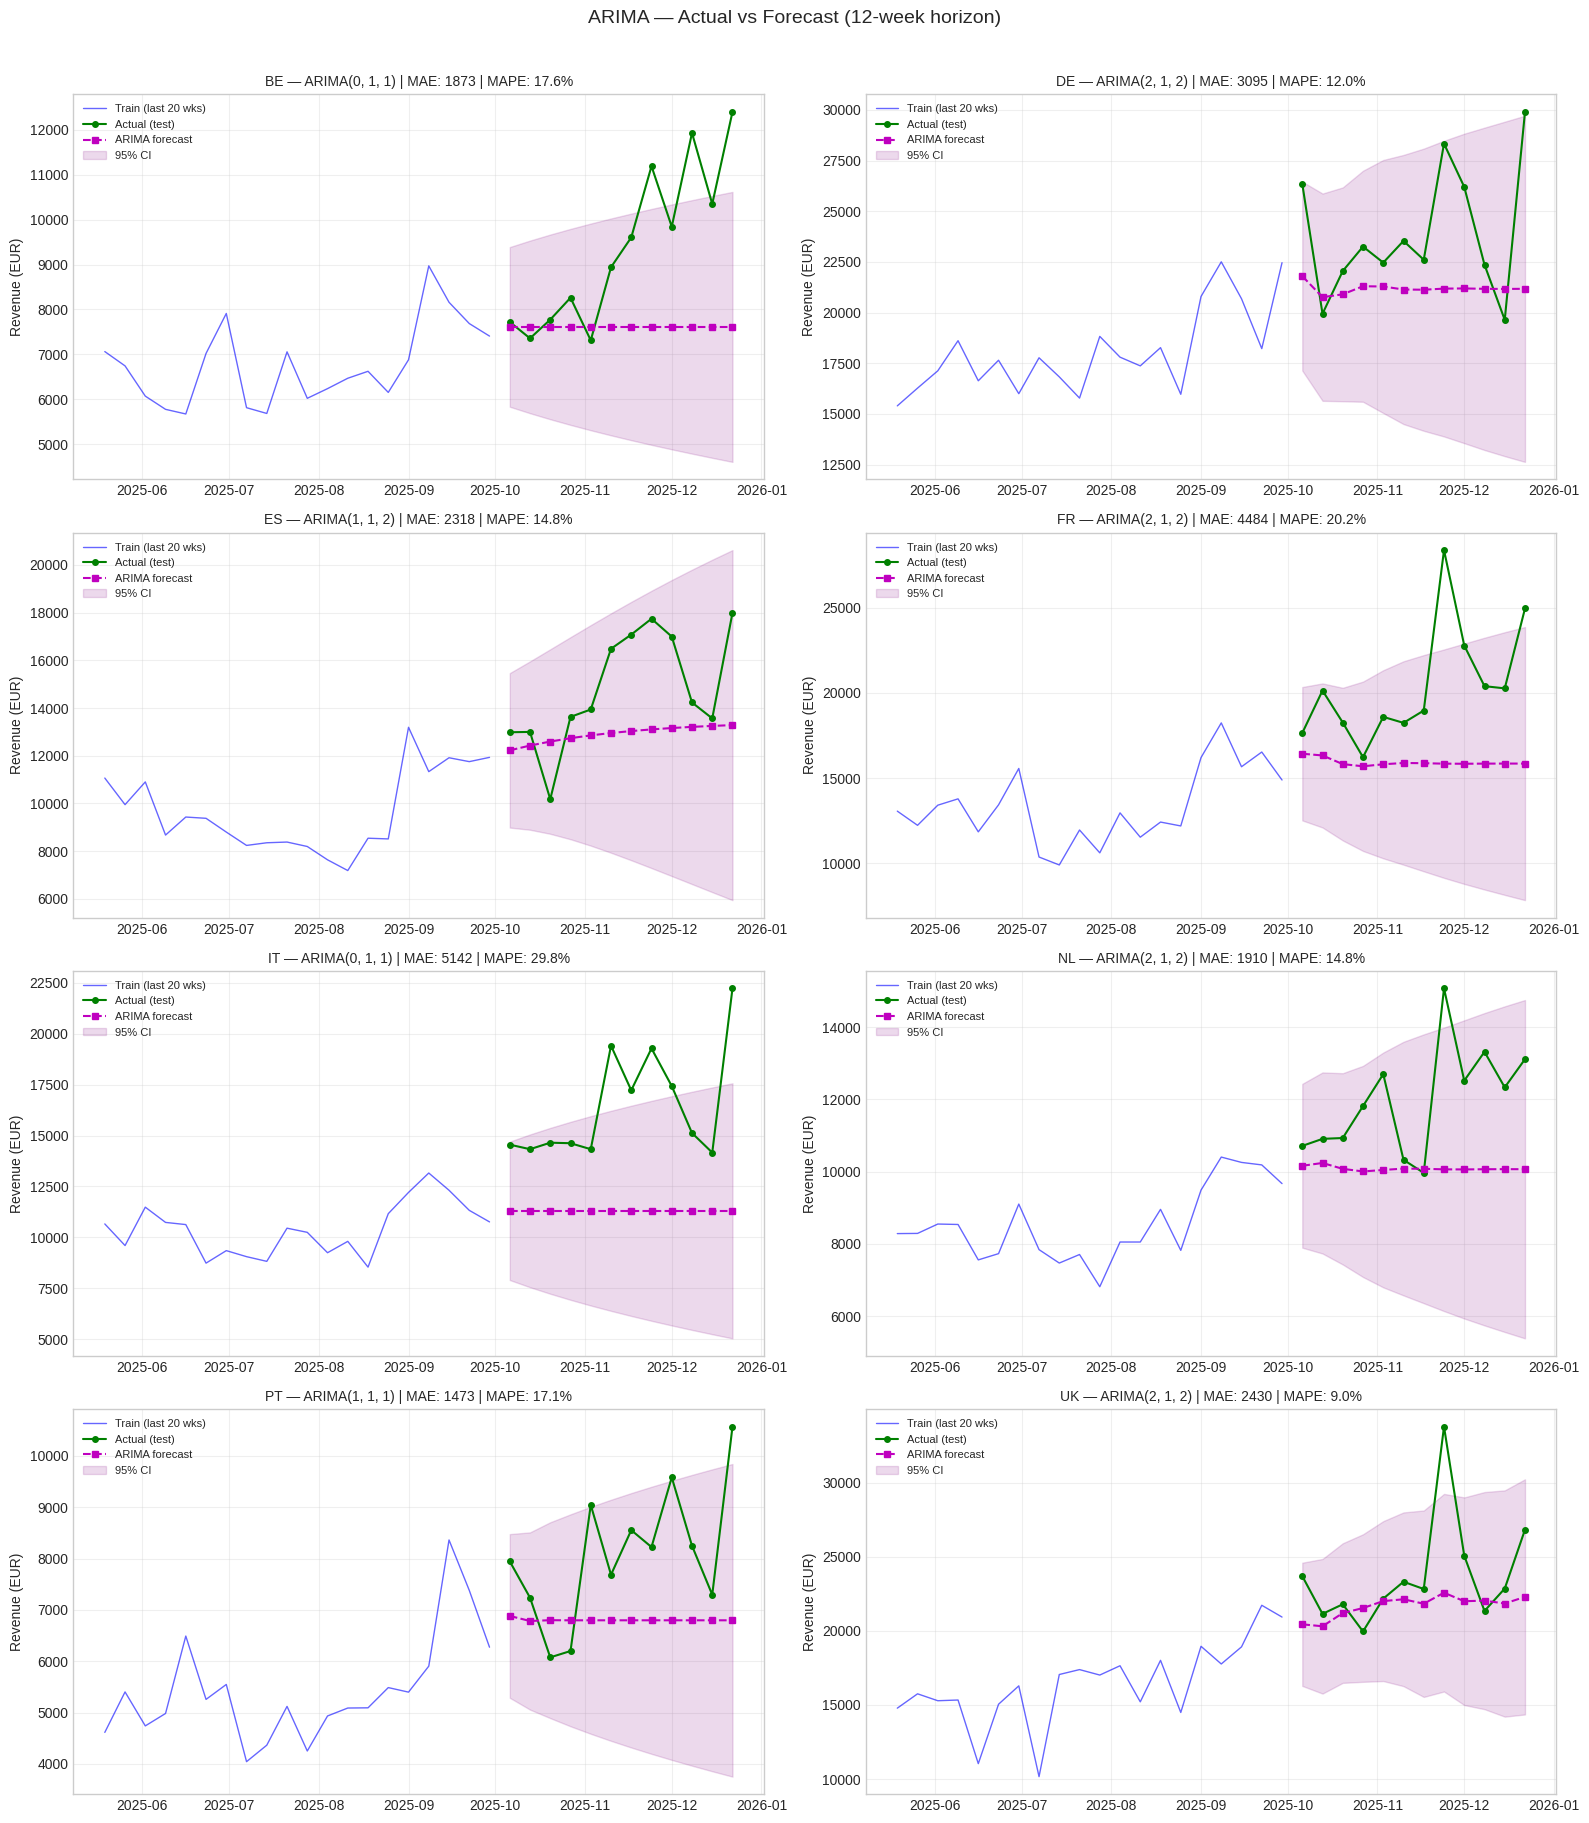

Forecast plot saved.


In [8]:
# Cell 7: Actual vs Predicted per country
fig, axes = plt.subplots(4, 2, figsize=(16, 18))

for idx, country in enumerate(countries):
    ax = axes[idx // 2, idx % 2]
    test_dates = pd.to_datetime(arima_test_dates[country])
    actual = arima_test_data[country]
    predicted = arima_predictions[country]
    conf_int = arima_conf_intervals[country]

    # Last 20 training points for context
    country_df = sales_df[sales_df.country == country].sort_values('week_start_date')
    train_tail = country_df.iloc[-(FORECAST_HORIZON+20):-FORECAST_HORIZON]

    ax.plot(train_tail['week_start_date'], train_tail['total_revenue_eur'],
            'b-', linewidth=1, alpha=0.6, label='Train (last 20 wks)')
    ax.plot(test_dates, actual,
            'g-o', linewidth=1.5, markersize=4, label='Actual (test)')
    ax.plot(test_dates, predicted,
            'm--s', linewidth=1.5, markersize=4, label='ARIMA forecast')
    ax.fill_between(test_dates, conf_int[:, 0], conf_int[:, 1],
                    alpha=0.15, color='purple', label='95% CI')

    mae = country_metrics[country]['mae']
    mape = country_metrics[country]['mape']
    order_str = f'{arima_models[country].order}'
    ax.set_title(f'{country} — ARIMA{order_str} | MAE: {mae:.0f} | '
                 f'MAPE: {mape:.1f}%', fontsize=10)
    ax.set_ylabel('Revenue (EUR)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle('ARIMA — Actual vs Forecast (12-week horizon)', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/arima_forecast_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Forecast plot saved.')

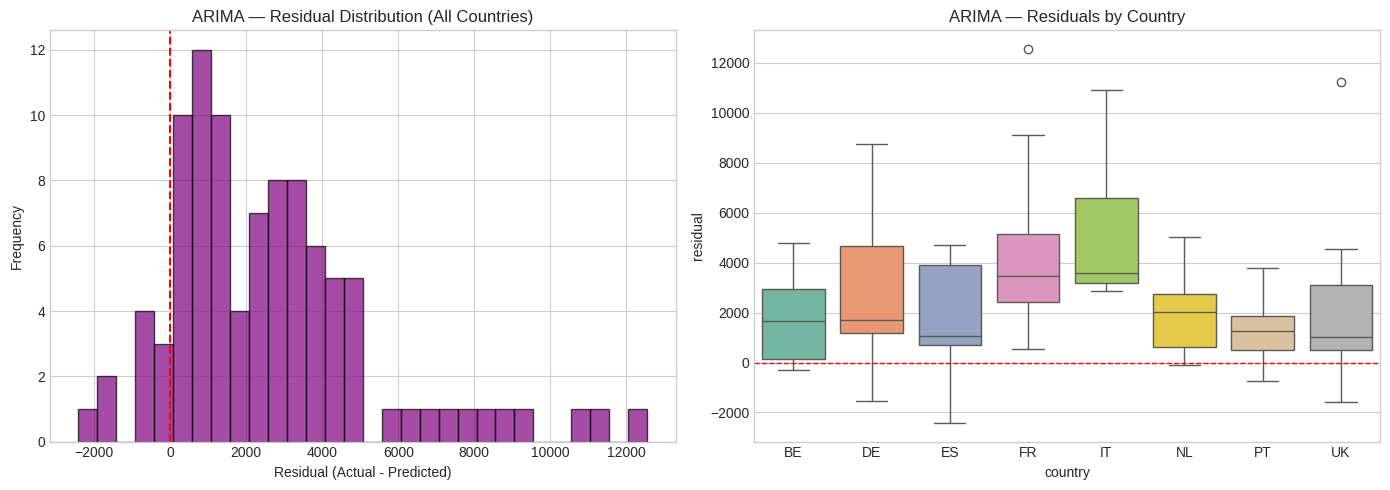

Residual analysis saved.


In [9]:
# Cell 8: Residual analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals = np.array(all_actuals) - np.array(all_predictions)

axes[0].hist(residuals, bins=30, edgecolor='black', alpha=0.7, color='purple')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_title('ARIMA — Residual Distribution (All Countries)')
axes[0].set_xlabel('Residual (Actual - Predicted)')
axes[0].set_ylabel('Frequency')

residual_data = []
for country in countries:
    actual = arima_test_data[country]
    predicted = arima_predictions[country]
    for r in (actual - predicted):
        residual_data.append({'country': country, 'residual': float(r)})

res_df = pd.DataFrame(residual_data)
sns.boxplot(data=res_df, x='country', y='residual', ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_title('ARIMA — Residuals by Country')

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/arima_residuals.png', dpi=150, bbox_inches='tight')
plt.show()
print('Residual analysis saved.')

## Exporting results

Saving metrics and forecasts to JSON for the 4-model comparison (Notebook 06).


In [10]:
# Cell 9: Save results JSON
results = {
    'model_name': 'ARIMA',
    'framework': 'pmdarima (Auto-ARIMA)',
    'timestamp': datetime.now().isoformat(),
    'configuration': {
        'approach': 'per-country auto_arima',
        'seasonal': True,
        'm': 52,
        'stepwise': True,
        'information_criterion': 'aic',
        'regressors': None,
        'forecast_horizon_weeks': FORECAST_HORIZON,
        'per_country_orders': {
            c: {'order': list(arima_orders[c]['order']),
                'seasonal_order': list(arima_orders[c]['seasonal_order']),
                'aic': round(arima_orders[c]['aic'], 2)}
            for c in countries
        },
    },
    'dataset': {
        'total_records': len(sales_df),
        'countries': countries,
        'date_range': f"{sales_df.week_start_date.min().date()} to "
                      f"{sales_df.week_start_date.max().date()}",
        'test_size_per_country': FORECAST_HORIZON,
    },
    'metrics': {
        'overall': {k: round(float(v), 4) for k, v in overall.items()},
        'per_country': {c: {k: round(float(v), 4) for k, v in m.items()}
                        for c, m in country_metrics.items()},
    },
    'training': {
        'total_time_seconds': round(total_training_time, 2),
        'per_country_seconds': {c: round(t, 2) for c, t in training_times.items()},
    },
    'forecasts': {
        country: {
            'dates': [str(pd.Timestamp(d).date()) for d in arima_test_dates[country]],
            'actual': arima_test_data[country].tolist(),
            'predicted': arima_predictions[country].tolist(),
            'lower_bound': arima_conf_intervals[country][:, 0].tolist(),
            'upper_bound': arima_conf_intervals[country][:, 1].tolist(),
        }
        for country in countries
    },
}

results_path = f'{RESULTS_DIR}/arima_results.json'
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f'Results saved to {results_path}')
print(f'\n=== ARIMA SUMMARY ===')
print(f'Overall MAE:   {overall["mae"]:.2f} EUR')
print(f'Overall RMSE:  {overall["rmse"]:.2f} EUR')
print(f'Overall MAPE:  {overall["mape"]:.2f}%')
print(f'Overall SMAPE: {overall["smape"]:.2f}%')
print(f'Training time: {total_training_time:.1f}s')

Results saved to /content/drive/MyDrive/ML_Prediction_Analysis/ARIMA_Results/arima_results.json

=== ARIMA SUMMARY ===
Overall MAE:   2840.43 EUR
Overall RMSE:  3833.99 EUR
Overall MAPE:  16.90%
Overall SMAPE: 19.27%
Training time: 60.3s


---

## Wrapping up

| Aspect | Detail |
|--------|--------|
| Model | Auto-ARIMA (SARIMAX) |
| Approach | Per-country fitting (8 models) |
| Parameter selection | Automatic via AIC |
| Seasonal period | m=13 (quarterly, for speed) |
| Regressors | None (pure time-series baseline) |
| Forecast horizon | 12 weeks |
| Hardware | CPU only |

What stood out:
1. ARIMA is the classical statistical baseline here — useful precisely because it has no domain knowledge baked in.
2. With no external regressors in this config, it can't react to promotions or the COVID disruption directly.
3. Seasonal ARIMA at m=13 captures the quarterly retail cycle reasonably well, even without the full yearly period.
4. It's noticeably sensitive to non-stationarity and structural breaks in the series.
5. Auto-selection means each country ends up with different (p,d,q) parameters — there's no single "ARIMA model" here, more like 8 tailored ones.

Next: LightGBM (Notebook 05), then the full 4-model comparison (Notebook 06).
